<a href="https://colab.research.google.com/github/lazy-arcanist/AVD_Praktikum_Adriel/blob/main/Proyek_AVD_Kaggle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan & Dashboard Analisis Data – Leaderboard Catur Model AI (Kaggle)
**Tugas Proyek Integrasi – Analisis & Visualisasi Data (AVD)** | Koding dan Kecerdasan Artifisial (KKA) – RPL, Fase F Kelas XI
**Dataset:** `kaggle_chess-text_leaderboard.csv` (Kaggle – benchmark *chess-text*)

## Identitas
| Keterangan | Isian |
|---|---|
| Nama Kelompok | Kelompok 5 |
| Kelas | XI RPL 8 |
| Anggota |  Abdurrahman Al Ghazi (No. Absen 1)|
|         | Adriel Winston Tjahja (No. Absen 2) |  
|         | Callista Filza Farzana S. (No. Absen 9) |
|         | Djibril Garudea Fairuz (No. Absen 11) |
| Tanggal Pengumpulan | 13 - 11 - 2026

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()   # pilih kaggle_chess-text_leaderboard.csv

## 1. Eksplorasi & Pembersihan Data

In [ ]:
df = pd.read_csv('kaggle_chess-text_leaderboard.csv')
print(df.head())
df.info()
print(df.isnull().sum())
print("Data duplikat:", df.duplicated().sum())

           Benchmark             Model  ... Lower_Confidence_Limit Boolean_Result
0  kaggle/chess-text   gemini-4-carbon  ...              37.768956            NaN
1  kaggle/chess-text   gemini-4-carbon  ...                    NaN            NaN
2  kaggle/chess-text   gemini-4-carbon  ...                    NaN            NaN
3  kaggle/chess-text  gemini-3.8-flash  ...              46.174445            NaN
4  kaggle/chess-text  gemini-3.8-flash  ...                    NaN            NaN

[5 rows x 15 columns]
<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Benchmark               126 non-null    str    
 1   Model                   126 non-null    str    
 2   Contestant              126 non-null    str    
 3   Contestant_Type         126 non-null    str    
 4   Config                  0 non-null      float64
 5   Harness        

In [ ]:
# data awal berbentuk "long" (1 model = 3 baris), diubah jadi 1 baris per model
w = df.pivot(index='Model', columns='Task_Name', values='Numerical_Result').reset_index()
w.columns = ['model', 'biaya_sen', 'token', 'skor']

w['keluarga'] = w['model'].str.split('-').str[0]   # gemini, gpt, claude, grok, ...
w['skor_per_sen'] = w['skor'] / w['biaya_sen']     # efisiensi

print(w.head())
print(w.describe())

                      model  biaya_sen  ...  keluarga  skor_per_sen
0  claude-fable-5-1-default  13.706117  ...    claude     55.547215
1  claude-fable-5-2-default   7.295504  ...    claude    180.013342
2          claude-haiku-5-5   0.210612  ...    claude   2821.067740
3   claude-opus-4-6-default  14.345059  ...    claude      3.506203
4   claude-opus-4-7-default  17.207561  ...    claude     16.522816

[5 rows x 6 columns]
       biaya_sen         token         skor  skor_per_sen
count  42.000000     42.000000    42.000000     42.000000
mean    9.592992   8975.190476   841.592749    334.336734
std     9.335686   6117.108907   415.174140    547.363336
min     0.210612   1530.000000     0.000000      0.000000
25%     2.704067   4683.000000   598.026846     52.933027
50%     7.154328   7227.000000   795.553323    141.466050
75%    14.616395  11433.250000  1221.587346    385.684170
max    40.278645  30103.000000  1646.300219   2821.067740


Tidak ada duplikat. Kolom `Config`, `Harness`, `Agent`, `Boolean_Result` kosong semua (tidak dipakai). Data diubah dari format *long* ke 1 baris per model, hasilnya 42 model.

## 2. Statistik Deskriptif

In [ ]:
print("Jumlah model        :", len(w))
print("Skor rata-rata      :", round(w['skor'].mean(), 1))
print("Skor median         :", round(w['skor'].median(), 1))
print("Biaya rata-rata     :", round(w['biaya_sen'].mean(), 2), "sen")
print("Biaya median        :", round(w['biaya_sen'].median(), 2), "sen")
print("Korelasi skor-biaya :", round(w['skor'].corr(w['biaya_sen']), 2))

print("\nSkor rata-rata per keluarga:")
print(w.groupby('keluarga')['skor'].mean().sort_values(ascending=False).round(1))

print("\n3 skor tertinggi:")
print(w.sort_values('skor', ascending=False).head(3)[['model', 'skor']])

print("\n3 model paling efisien (skor per sen):")
print(w.sort_values('skor_per_sen', ascending=False).head(3)[['model', 'skor', 'biaya_sen', 'skor_per_sen']])

Jumlah model        : 42
Skor rata-rata      : 841.6
Skor median         : 795.6
Biaya rata-rata     : 9.59 sen
Biaya median        : 7.15 sen
Korelasi skor-biaya : 0.07

Skor rata-rata per keluarga:
keluarga
gemini      1370.6
o3           925.1
gpt          899.5
grok         702.8
claude       563.2
deepseek      86.3
Name: skor, dtype: float64

3 skor tertinggi:
               model         skor
20   gemini-4-carbon  1646.300219
18  gemini-3.8-flash  1457.957920
29       gpt-6-astra  1435.210118

3 model paling efisien (skor per sen):
               model         skor  biaya_sen  skor_per_sen
2   claude-haiku-5-5   594.151439   0.210612   2821.067740
30        gpt-6-luna   449.603332   0.229984   1954.930609
17  gemini-3.7-flash  1397.234603   1.186382   1177.727593


Model terbaik **gemini-4-carbon** (±1.646). Skor mean (±842) dan median (±796) berdekatan. Korelasi skor-biaya hanya **0,07**, jadi mahal belum tentu bagus. Paling efisien **claude-haiku-5-5** (±2.821 poin per sen). Keluarga **gemini** punya rata-rata skor tertinggi.

## 3. Visualisasi

**Bar Chart**

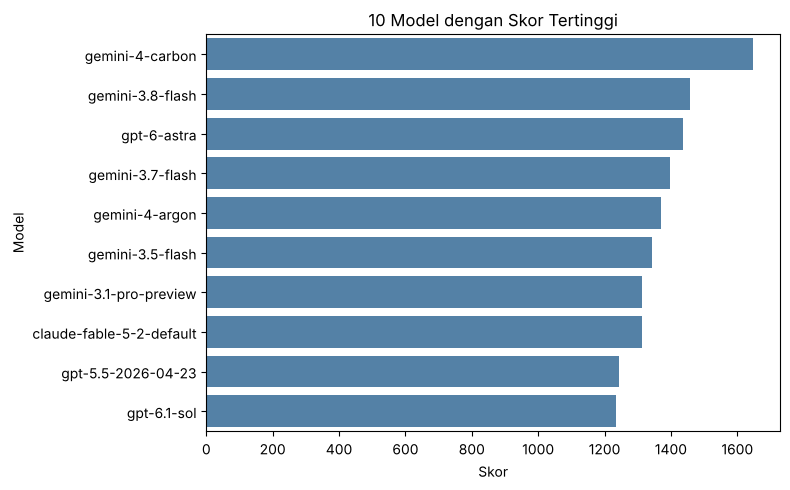

In [ ]:
top10 = w.sort_values('skor', ascending=False).head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=top10['skor'], y=top10['model'], color='steelblue')
plt.title('10 Model dengan Skor Tertinggi')
plt.xlabel('Skor')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

**Insight:** gemini-4-carbon unggul dengan skor ±1.646. Keluarga gemini mengisi 6 dari 10 peringkat teratas.

**Line Chart** (tren antar-versi Gemini; data hanya punya satu waktu evaluasi)

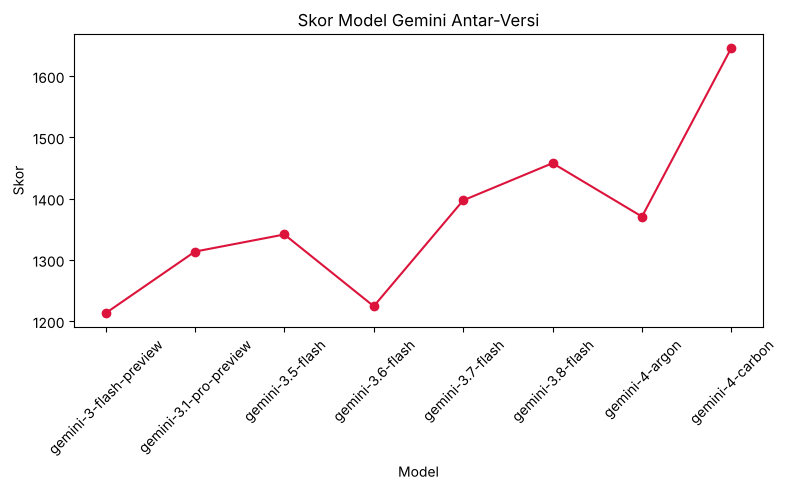

In [ ]:
g = w[w['keluarga'] == 'gemini'].sort_values('model')

plt.figure(figsize=(8,5))
plt.plot(g['model'], g['skor'], marker='o', color='crimson')
plt.title('Skor Model Gemini Antar-Versi')
plt.xlabel('Model')
plt.ylabel('Skor')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** skor Gemini naik dari ±1.213 (gemini-3-flash-preview) ke ±1.646 (gemini-4-carbon), sekitar +36%. Kenaikannya tidak mulus karena sempat turun di versi 3.6 dan 4-argon.

**Scatter Plot**

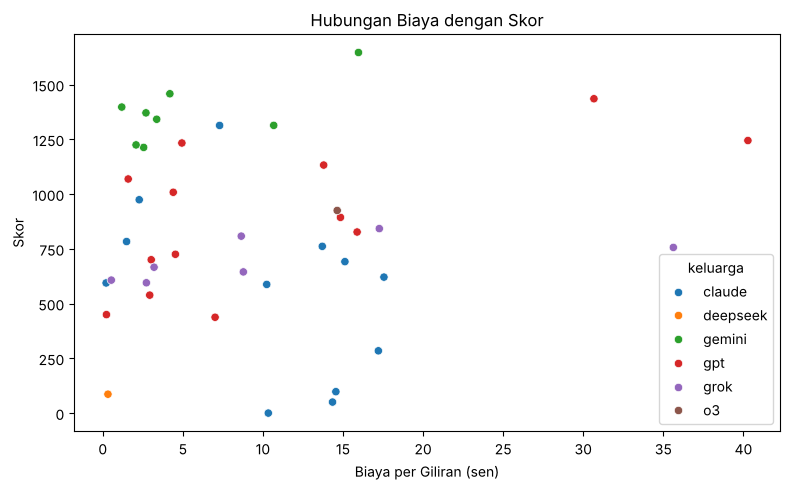

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=w, x='biaya_sen', y='skor', hue='keluarga')
plt.title('Hubungan Biaya dengan Skor')
plt.xlabel('Biaya per Giliran (sen)')
plt.ylabel('Skor')
plt.tight_layout()
plt.show()

**Insight:** titik tersebar tanpa pola naik (korelasi ±0,07). gpt-5.5-2026-04-23 berbiaya ±40,3 sen dengan skor ±1.244, sedangkan gemini-3.7-flash hanya ±1,19 sen dengan skor ±1.397.

**Histogram**

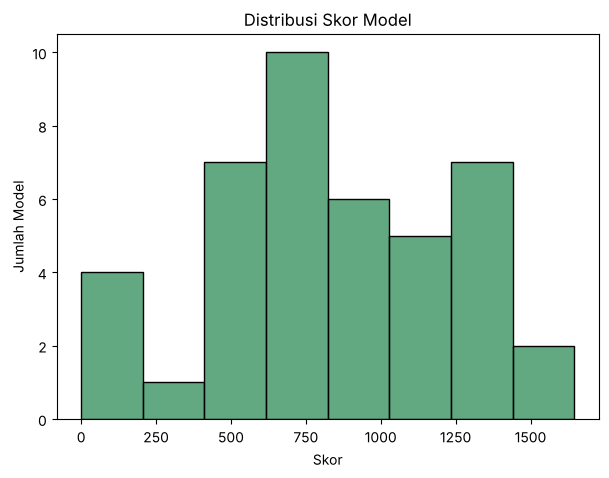

In [ ]:
plt.figure(figsize=(7,5))
sns.histplot(w['skor'], bins=8, color='seagreen')
plt.title('Distribusi Skor Model')
plt.xlabel('Skor')
plt.ylabel('Jumlah Model')
plt.show()

**Insight:** distribusi cukup simetris karena mean dan median berdekatan. Setengah dari model berskor sekitar 600-1.200, dan hanya 3 model yang di atas 1.400.

**Boxplot**

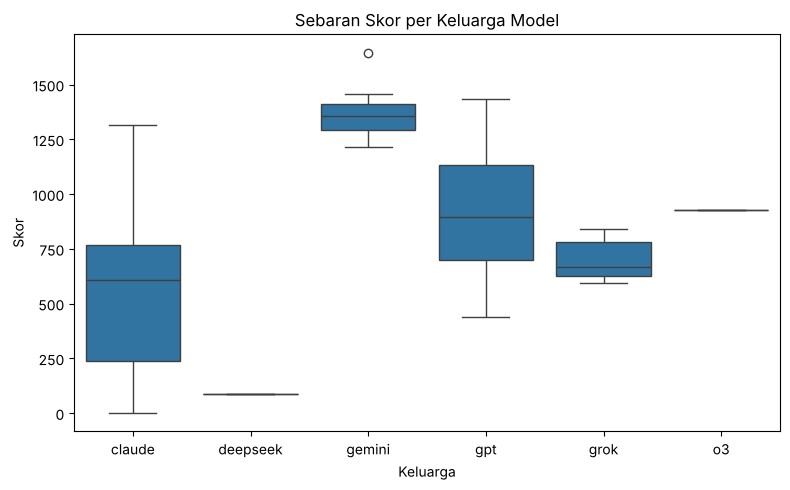

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=w, x='keluarga', y='skor')
plt.title('Sebaran Skor per Keluarga Model')
plt.xlabel('Keluarga')
plt.ylabel('Skor')
plt.tight_layout()
plt.show()

**Insight:** gemini punya median tertinggi (±1.356) dan sebaran paling sempit. Claude bersebaran sangat lebar (0 sampai ±1.313), artinya kualitas antar-versinya sangat bervariasi.

## 4. Deteksi Outlier (Aturan IQR)

Batas atas outlier biaya: 32.5 sen
                 model  biaya_sen
25  gpt-5.5-2026-04-23  40.278645
34         grok-4-0709  35.623729


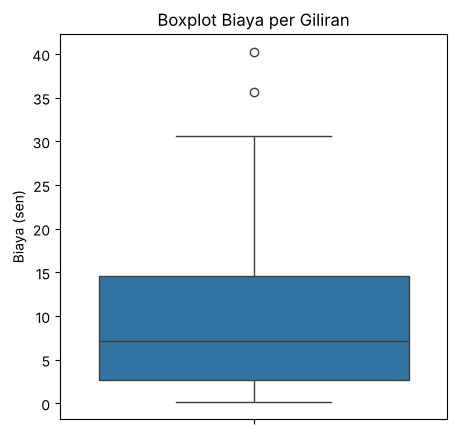

In [ ]:
Q1 = w['biaya_sen'].quantile(0.25)
Q3 = w['biaya_sen'].quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
print("Batas atas outlier biaya:", round(batas_atas, 1), "sen")
print(w[w['biaya_sen'] > batas_atas][['model', 'biaya_sen']])

plt.figure(figsize=(5,5))
sns.boxplot(y=w['biaya_sen'])
plt.title('Boxplot Biaya per Giliran')
plt.ylabel('Biaya (sen)')
plt.show()

Outlier biaya: **gpt-5.5-2026-04-23** (±40,3 sen) dan **grok-4-0709** (±35,6 sen), keduanya di atas batas ±32,5 sen. Kemungkinan penyebab: model besar dengan tarif per token tinggi dan pemakaian token yang banyak.

## 5. Dashboard

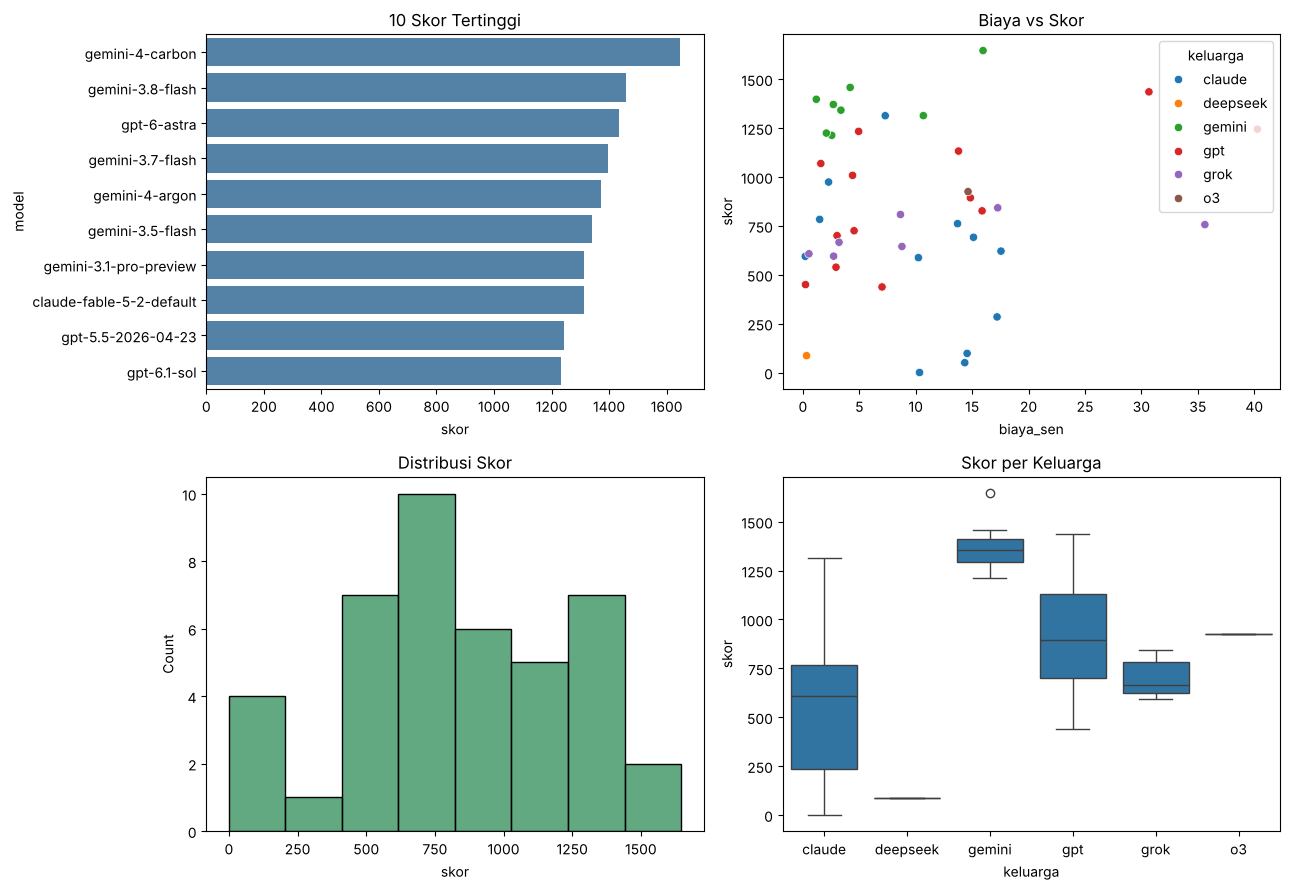

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))

sns.barplot(x=top10['skor'], y=top10['model'], color='steelblue', ax=axes[0,0])
axes[0,0].set_title('10 Skor Tertinggi')

sns.scatterplot(data=w, x='biaya_sen', y='skor', hue='keluarga', ax=axes[0,1])
axes[0,1].set_title('Biaya vs Skor')

sns.histplot(w['skor'], bins=8, color='seagreen', ax=axes[1,0])
axes[1,0].set_title('Distribusi Skor')

sns.boxplot(data=w, x='keluarga', y='skor', ax=axes[1,1])
axes[1,1].set_title('Skor per Keluarga')

plt.tight_layout()
plt.show()

**Insight:** gemini mendominasi peringkat atas, biaya tidak berhubungan jelas dengan skor, dan kualitas antar-keluarga berbeda jauh. Pilih model dengan melihat **skor dan biaya sekaligus**.

## 6. Laporan Rekomendasi

Dari 42 model pada benchmark catur berbasis teks, skor berkisar 0 sampai 1.646 dengan rata-rata 842 dan median 796. Model terbaik adalah gemini-4-carbon (1.646) dengan biaya 15,96 sen per giliran, jauh di atas median 7,15 sen. Korelasi skor dan biaya hanya 0,07, sehingga model mahal tidak otomatis lebih baik. Contohnya gpt-5.5-2026-04-23 berbiaya 40,28 sen dengan skor 1.244, sedangkan gemini-3.7-flash mencapai skor 1.397 dengan biaya hanya 1,19 sen. Artinya, perusahaan perlu menilai model dari skor dan biayanya sekaligus, bukan dari harganya saja.

Rekomendasi kami: (1) untuk kualitas maksimum dengan anggaran longgar, gunakan gemini-4-carbon; (2) untuk keseimbangan kualitas dan biaya, pilih gemini-3.7-flash, gemini-4-argon, atau gpt-6.1-terra yang berskor tinggi dengan biaya di bawah 3 sen; (3) untuk anggaran sangat ketat, claude-haiku-5-5 paling efisien (sekitar 2.821 poin per sen) walau skornya sedang (594); (4) hindari model mahal berskor rendah seperti claude-opus-4-7-default (284 poin pada 17,2 sen); (5) evaluasi ulang model outlier biaya, yaitu gpt-5.5-2026-04-23 dan grok-4-0709, sebelum dipakai massal.

Dari sisi keluarga, gemini paling konsisten (rata-rata 1.371, rentang 1.213 sampai 1.646), sedangkan claude sangat bervariasi (0 sampai 1.313), sehingga pemilihan versinya harus teliti. Keluarga grok dan gpt berada di tengah, dengan rata-rata skor masing-masing 703 dan 900. Data hanya mewakili satu benchmark pada satu waktu evaluasi, jadi perlu diuji ulang pada tugas nyata perusahaan.